# Week 7 — Full-dataset YOLO nano for colony detection

**Machine Learning for Bioinformatics**

This notebook trains **YOLO nano detectors on the complete student CVAT set** (all three annotation batches) and keeps the checkpoint with the best validation score for deployment.

| Zip | Batch | Format | Images |
|---|---|---|---|
| `pt1_obb.zip` | partner 1 | YOLO OBB (`class` + 8 corner coords) | 20 |
| `colonies_2.zip` | partner 2 | CVAT 1.1 XML (boxes + polygons) | 20 |
| `colonies_3.zip` | partner 3 | CVAT 1.1 XML (boxes + a few polygons) | 19 |

Together that is the full `hometask/` set (~59 plates). Oriented boxes and polygons are converted to axis-aligned YOLO detect labels: `class xc yc w h` in `[0, 1]`.

**Protocol**

1. Unpack, convert, and explore the three batches (pairing, object counts, box sizes, overlays).
2. Freeze one stratified train/val split of the **full** dataset.
3. Train several **nano** families with the same hyperparameters: `yolov8n`, `yolo11n`, `yolo26n`.
4. Take the best nano and retrain it with **colony-reasonable augmentations** only (circular objects on plates).
5. Copy the winning weights plus an ONNX export into `homework/yolo_full_work/deployment/`.

The earlier CPU homework notebook (`02_yolo_colony_detection_cpu.ipynb`) used 10 epochs at 320 px on a partial set. This notebook aims at **higher scores**: 640 px, more epochs, all 59 images, and a held-out val set that includes every annotator.


## 0. Setup

GPU is used when CUDA is available. Set `FORCE_CPU = True` to match the previous local CPU run. Set `SMOKE_TEST = True` for a 5-epoch dry run before the full comparison.


In [1]:
from pathlib import Path
import json
import random
import re
import shutil
import zipfile
from xml.etree import ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import torch
from ultralytics import YOLO

RANDOM_STATE = 221026
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

FORCE_CPU = False
SMOKE_TEST = False
RUN_TRAINING = True
RUN_AUGMENTATION = True
RUN_EXPORT = True
SHOW_PLOTS = True

NANO_MODELS = {
    'YOLOv8n': 'yolov8n.pt',
    'YOLO11n': 'yolo11n.pt',
    'YOLO26n': 'yolo26n.pt',
}

YOLO_EPOCHS = 5 if SMOKE_TEST else 50
YOLO_IMGSZ = 640
YOLO_MAX_DET = 700  # dense plates exceed the default 300
VAL_FRACTION = 0.2
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}

use_cuda = (not FORCE_CPU) and torch.cuda.is_available()
YOLO_DEVICE = 0 if use_cuda else 'cpu'
YOLO_WORKERS = 2 if use_cuda else 0
YOLO_AMP = bool(use_cuda)
YOLO_BATCH = 8 if use_cuda else 4

print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('Using device:', YOLO_DEVICE)
print('AMP:', YOLO_AMP, '| batch:', YOLO_BATCH, '| imgsz:', YOLO_IMGSZ, '| epochs:', YOLO_EPOCHS)
print('CPU threads:', torch.get_num_threads())


PyTorch: 2.14.1+cu130
CUDA available: False
Using device: cpu
AMP: False | batch: 4 | imgsz: 640 | epochs: 50
CPU threads: 10


## 1. Locate week 7 and unpack the three CVAT zips


In [2]:
def locate_week7_root():
    current = Path.cwd().resolve()
    for base in (current, *current.parents):
        for candidate in (base, base / 'week7'):
            zips = [candidate / name for name in ('pt1_obb.zip', 'colonies_2.zip', 'colonies_3.zip')]
            if all(path.exists() for path in zips):
                return candidate
            if (candidate / 'detection').is_dir():
                return candidate
    return current


WEEK7_ROOT = locate_week7_root()
ZIP_PATHS = {
    'pt1_obb': WEEK7_ROOT / 'pt1_obb.zip',
    'colonies_2': WEEK7_ROOT / 'colonies_2.zip',
    'colonies_3': WEEK7_ROOT / 'colonies_3.zip',
}
WORK_ROOT = WEEK7_ROOT / 'homework' / 'yolo_full_work'
RAW_ROOTS = {
    'pt1_obb': WORK_ROOT / 'raw_pt1',
    'colonies_2': WORK_ROOT / 'raw_colonies_2',
    'colonies_3': WORK_ROOT / 'raw_colonies_3',
}
HOMETASK_DIR = WEEK7_ROOT / 'hometask'

print('WEEK7_ROOT:', WEEK7_ROOT)
for name, path in ZIP_PATHS.items():
    print(f'{name} exists: {path.exists()}  {path}')
    assert path.exists(), f'Missing {path}'


def unzip_clean(zip_path, dest):
    if dest.exists():
        shutil.rmtree(dest)
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(dest)
    return dest


for name, zip_path in ZIP_PATHS.items():
    dest = unzip_clean(zip_path, RAW_ROOTS[name])
    print('Unpacked', name, '->', dest)


WEEK7_ROOT: /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7
pt1_obb exists: True  /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/pt1_obb.zip
colonies_2 exists: True  /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/colonies_2.zip
colonies_3 exists: True  /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/colonies_3.zip
Unpacked pt1_obb -> /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_full_work/raw_pt1
Unpacked colonies_2 -> /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_full_work/raw_colonies_2
Unpacked colonies_3 -> /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_full_work/raw_colonies_3


## 2. Convert OBB and CVAT XML to YOLO detect labels

Standard detect labels are five numbers: `class_id  x_center  y_center  width  height`, normalized to `[0, 1]`.

- `pt1_obb` stores four corners. We take the axis-aligned bounding box of those corners.
- `colonies_2` and `colonies_3` mix CVAT `<box>` rectangles and a few `<polygon>` shapes. Both become the same five-number format.
- Overlaps inside one XML image are merged with IoU 0.7, keeping manual boxes over imported polygons.


In [3]:
def sanitize_stem(name):
    stem = Path(name).stem.strip()
    return re.sub(r'[^A-Za-z0-9_.-]+', '_', stem).strip('_') or 'image'


def clip01(value):
    return float(np.clip(value, 0.0, 1.0))


def corners_to_xywh(xs, ys):
    x_min, x_max = min(xs), max(xs)
    y_min, y_max = min(ys), max(ys)
    width = max(0.0, x_max - x_min)
    height = max(0.0, y_max - y_min)
    if width <= 0 or height <= 0:
        return None
    return (
        clip01((x_min + x_max) / 2),
        clip01((y_min + y_max) / 2),
        clip01(width),
        clip01(height),
    )


def pixel_aabb_to_xywh(x0, y0, x1, y1, width, height):
    x0, x1 = sorted((float(x0), float(x1)))
    y0, y1 = sorted((float(y0), float(y1)))
    x0 = np.clip(x0, 0, width)
    x1 = np.clip(x1, 0, width)
    y0 = np.clip(y0, 0, height)
    y1 = np.clip(y1, 0, height)
    return corners_to_xywh([x0 / width, x1 / width], [y0 / height, y1 / height])


def xywh_to_xyxy(xc, yc, w, h):
    return np.array([xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2], dtype=float)


def box_iou(a, b):
    left, top = max(a[0], b[0]), max(a[1], b[1])
    right, bottom = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, right - left) * max(0.0, bottom - top)
    area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0


def nms_records(records, iou_thr=0.7):
    if not records:
        return []
    order = sorted(range(len(records)), key=lambda i: records[i][5], reverse=True)
    keep = []
    suppressed = set()
    for i in order:
        if i in suppressed:
            continue
        keep.append(i)
        box_i = xywh_to_xyxy(*records[i][1:5])
        for j in order:
            if j in suppressed or j == i:
                continue
            if box_iou(box_i, xywh_to_xyxy(*records[j][1:5])) >= iou_thr:
                suppressed.add(j)
    return [records[i][:5] for i in sorted(keep)]


def write_yolo_txt(path, records):
    lines = [f'{int(cls)} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}' for cls, xc, yc, w, h in records]
    path.write_text('\n'.join(lines) + ('\n' if lines else ''), encoding='utf-8')


def parse_obb_label(label_path):
    records = []
    text = Path(label_path).read_text(encoding='utf-8')
    for line_number, line in enumerate(text.splitlines(), start=1):
        if not line.strip():
            continue
        parts = line.split()
        if len(parts) == 5:
            cls, xc, yc, w, h = int(parts[0]), *map(float, parts[1:])
            records.append((cls, clip01(xc), clip01(yc), clip01(w), clip01(h), 1.0))
            continue
        if len(parts) != 9:
            raise ValueError(f'{label_path}:{line_number} expected 5 or 9 values, got {len(parts)}')
        cls = int(parts[0])
        coords = list(map(float, parts[1:]))
        converted = corners_to_xywh(coords[0::2], coords[1::2])
        if converted is not None:
            records.append((cls, *converted, 1.0))
    return nms_records(records)


def collect_pt1_pairs(raw_root):
    image_dir = raw_root / 'images' / 'train'
    label_dir = raw_root / 'labels' / 'train'
    pairs = []
    for image_path in sorted(image_dir.iterdir()):
        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        label_path = label_dir / f'{image_path.stem}.txt'
        pairs.append((image_path, label_path if label_path.exists() else None))
    return pairs


def parse_cvat_xml(xml_path, image_root):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    pairs = []
    for image_node in root.findall('image'):
        name = image_node.get('name')
        width = float(image_node.get('width'))
        height = float(image_node.get('height'))
        image_path = image_root / name
        if not image_path.exists():
            matches = list(image_root.rglob(Path(name).name))
            image_path = matches[0] if matches else None
        records = []
        for box in image_node.findall('box'):
            converted = pixel_aabb_to_xywh(
                box.get('xtl'), box.get('ytl'), box.get('xbr'), box.get('ybr'),
                width, height,
            )
            if converted is None:
                continue
            score = 1.0 if box.get('source') == 'manual' else 0.5
            records.append((0, *converted, score))
        for polygon in image_node.findall('polygon'):
            points = []
            for pair in polygon.get('points', '').split(';'):
                if not pair.strip():
                    continue
                x_str, y_str = pair.split(',')
                points.append((float(x_str), float(y_str)))
            if len(points) < 3:
                continue
            xs = [x / width for x, _ in points]
            ys = [y / height for _, y in points]
            converted = corners_to_xywh(xs, ys)
            if converted is None:
                continue
            score = 1.0 if polygon.get('source') == 'manual' else 0.4
            records.append((0, *converted, score))
        pairs.append({
            'name': name,
            'image_path': image_path,
            'width': width,
            'height': height,
            'records': nms_records(records),
            'n_box_raw': len(image_node.findall('box')),
            'n_poly_raw': len(image_node.findall('polygon')),
        })
    return pairs


pt1_pairs = collect_pt1_pairs(RAW_ROOTS['pt1_obb'])
print('pt1 images:', len(pt1_pairs), '| missing labels:', sum(label is None for _, label in pt1_pairs))

xml_batches = {}
for batch in ('colonies_2', 'colonies_3'):
    xml_path = RAW_ROOTS[batch] / 'annotations.xml'
    xml_batches[batch] = parse_cvat_xml(xml_path, RAW_ROOTS[batch] / 'images')
    n_missing = sum(item['image_path'] is None for item in xml_batches[batch])
    n_box = sum(item['n_box_raw'] for item in xml_batches[batch])
    n_poly = sum(item['n_poly_raw'] for item in xml_batches[batch])
    print(f'{batch}: {len(xml_batches[batch])} images, missing files={n_missing}, raw boxes={n_box}, raw polygons={n_poly}')


pt1 images: 20 | missing labels: 0
colonies_2: 20 images, missing files=0, raw boxes=753, raw polygons=1450
colonies_3: 19 images, missing files=0, raw boxes=801, raw polygons=7


## 3. Data exploration

Checks before training: every image opens, every image has a label, coordinates are in `[0, 1]`, the three zips do not overlap, and together they cover `hometask/`. Box-size histograms later justify 640 px and a high `max_det`.


In [4]:
def inventory_image(path, source, records, original_name=None):
    row = {
        'source': source,
        'file': original_name or path.name,
        'stem': Path(original_name or path.name).name,
        'readable': False,
        'label_ok': False,
        'objects': len(records),
        'empty': len(records) == 0,
        'mean_box_w': np.nan,
        'mean_box_h': np.nan,
        'median_box_area': np.nan,
        'min_box_area': np.nan,
        'max_box_area': np.nan,
        'aspect_mean': np.nan,
    }
    try:
        with Image.open(path) as image:
            array = np.asarray(image)
            row.update({
                'readable': True,
                'format': image.format,
                'mode': image.mode,
                'width': image.width,
                'height': image.height,
                'dtype': str(array.dtype),
                'channels': 1 if array.ndim == 2 else array.shape[-1],
                'min_intensity': float(array.min()),
                'max_intensity': float(array.max()),
            })
    except Exception as exc:
        row['error'] = str(exc)
        return row
    ok = True
    widths, heights, areas, aspects = [], [], [], []
    for cls, xc, yc, w, h in records:
        if cls != 0 or not (0 <= xc <= 1 and 0 <= yc <= 1 and 0 < w <= 1 and 0 < h <= 1):
            ok = False
            continue
        widths.append(w)
        heights.append(h)
        areas.append(w * h)
        aspects.append(w / h if h > 0 else np.nan)
    row['label_ok'] = ok and len(records) == len(widths)
    if widths:
        row['mean_box_w'] = float(np.mean(widths))
        row['mean_box_h'] = float(np.mean(heights))
        row['median_box_area'] = float(np.median(areas))
        row['min_box_area'] = float(np.min(areas))
        row['max_box_area'] = float(np.max(areas))
        row['aspect_mean'] = float(np.nanmean(aspects))
    return row


samples = []  # list of dicts: source, image_path, records, original_name

pt1_converted = []
for image_path, label_path in pt1_pairs:
    records = parse_obb_label(label_path) if label_path is not None else []
    pt1_converted.append((image_path, records))
    samples.append({'source': 'pt1_obb', 'image_path': image_path, 'records': records, 'original_name': image_path.name})

xml_converted = {batch: [] for batch in xml_batches}
for batch, items in xml_batches.items():
    for item in items:
        xml_converted[batch].append((item['image_path'], item['records'], item['name']))
        samples.append({
            'source': batch,
            'image_path': item['image_path'],
            'records': item['records'],
            'original_name': item['name'],
        })

inventory_rows = []
for sample in samples:
    if sample['image_path'] is None:
        inventory_rows.append({
            'source': sample['source'],
            'file': sample['original_name'],
            'readable': False,
            'label_ok': False,
            'objects': len(sample['records']),
        })
        continue
    inventory_rows.append(inventory_image(
        sample['image_path'], sample['source'], sample['records'], sample['original_name'],
    ))

inventory = pd.DataFrame(inventory_rows)
display(inventory.head(12))

summary = inventory.groupby('source').agg(
    images=('file', 'count'),
    readable=('readable', 'sum'),
    label_ok=('label_ok', 'sum'),
    empty=('empty', 'sum'),
    objects=('objects', 'sum'),
    mean_objects=('objects', 'mean'),
    min_objects=('objects', 'min'),
    max_objects=('objects', 'max'),
    mean_aspect=('aspect_mean', 'mean'),
).reset_index()
display(summary)
print('Total images:', len(inventory), '| total objects:', int(inventory['objects'].sum()))
print('Unreadable:', int((~inventory['readable']).sum()), '| bad labels:', int((~inventory['label_ok']).sum()))


,source,file,stem,readable,label_ok,objects,empty,mean_box_w,mean_box_h,median_box_area,...,max_box_area,aspect_mean,format,mode,width,height,dtype,channels,min_intensity,max_intensity
0,pt1_obb,19 open.jpg,19 open.jpg,True,True,38,False,0.015600,0.022691,0.000352,...,0.000599,0.689668,JPEG,RGB,850,567,uint8,3,0.0,255.0
1,pt1_obb,21 count.jpg,21 count.jpg,True,True,38,False,0.014487,0.020662,0.000283,...,0.000551,0.703659,JPEG,RGB,850,567,uint8,3,0.0,255.0
2,pt1_obb,40 open.jpg,40 open.jpg,True,True,33,False,0.052569,0.082561,0.003790,...,0.020099,0.640997,JPEG,RGB,850,567,uint8,3,0.0,255.0
3,pt1_obb,702.jpg,702.jpg,True,True,274,False,0.015977,0.015587,0.000247,...,0.000572,1.045699,JPEG,RGB,850,834,uint8,3,0.0,255.0
4,pt1_obb,776.jpg,776.jpg,True,True,345,False,0.013798,0.013581,0.000186,...,0.000422,1.026375,JPEG,RGB,850,830,uint8,3,0.0,255.0
5,pt1_obb,"Plate 1 with cfu count, dark.jpg","Plate 1 with cfu count, dark.jpg",True,True,38,False,0.046773,0.048544,0.002261,...,0.003025,0.964941,JPEG,L,720,720,uint8,1,15.0,255.0
6,pt1_obb,"Plate 2 with cfu count, dark.jpg","Plate 2 with cfu count, dark.jpg",True,True,37,False,0.052758,0.053244,0.002903,...,0.003498,0.997906,JPEG,L,720,720,uint8,1,17.0,255.0
7,pt1_obb,Staph 3 RAW.png,Staph 3 RAW.png,True,True,273,False,0.014251,0.019699,0.000279,...,0.000539,0.732935,PNG,RGB,1920,1440,uint8,3,2.0,255.0
8,pt1_obb,Staph 6 RAW.png,Staph 6 RAW.png,True,True,27,False,0.018483,0.026148,0.000505,...,0.000595,0.709090,PNG,RGB,1920,1440,uint8,3,1.0,255.0
9,pt1_obb,Staph 7 RAW.png,Staph 7 RAW.png,True,True,20,False,0.017250,0.025125,0.000463,...,0.000598,0.688428,PNG,RGB,1920,1440,uint8,3,1.0,255.0


,source,images,readable,label_ok,empty,objects,mean_objects,min_objects,max_objects,mean_aspect
0,colonies_2,20,20,20,0,2203,110.150000,7,607,0.843131
1,colonies_3,19,19,19,0,808,42.526316,2,116,0.909554
2,pt1_obb,20,20,20,0,1893,94.650000,7,468,0.876174


Total images: 59 | total objects: 4904
Unreadable: 0 | bad labels: 0


Overlap pt1 vs colonies_2: []
Overlap pt1 vs colonies_3: []
Overlap colonies_2 vs colonies_3: []
hometask images: 59
labelled but not in hometask: []
hometask not in any zip: []


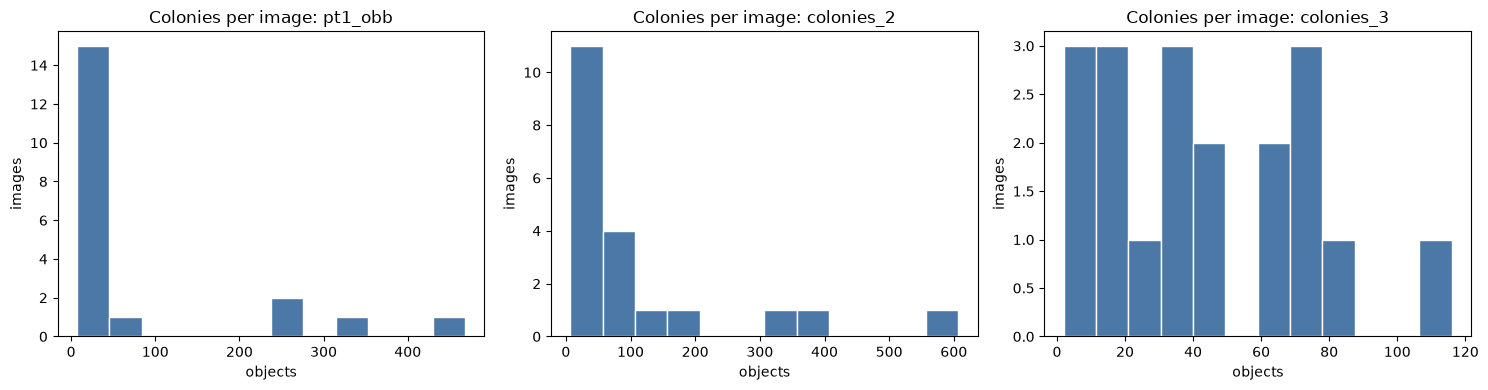

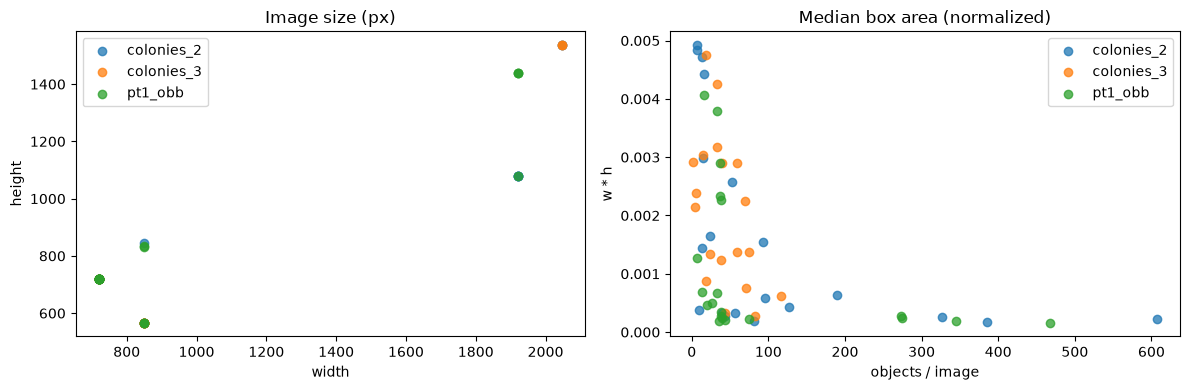

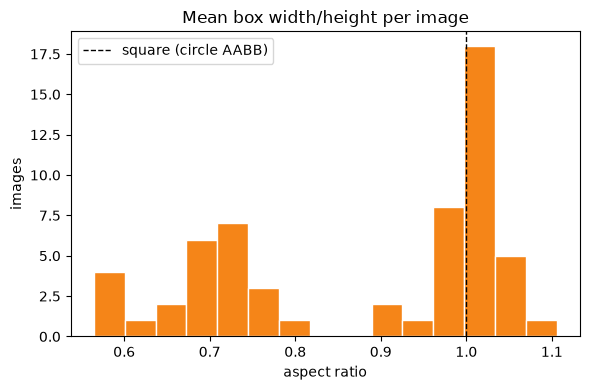

In [5]:
# Filename overlap across zips and coverage of hometask/
def norm_name(name):
    return re.sub(r'\s+', ' ', Path(name).name.strip().lower())


by_source = {
    source: {norm_name(name) for name in group['file']}
    for source, group in inventory.groupby('source')
}
print('Overlap pt1 vs colonies_2:', sorted(by_source['pt1_obb'] & by_source['colonies_2']))
print('Overlap pt1 vs colonies_3:', sorted(by_source['pt1_obb'] & by_source['colonies_3']))
print('Overlap colonies_2 vs colonies_3:', sorted(by_source['colonies_2'] & by_source['colonies_3']))

labelled = set()
for names in by_source.values():
    labelled |= names

if HOMETASK_DIR.is_dir():
    hometask = {norm_name(path.name) for path in HOMETASK_DIR.iterdir() if path.suffix.lower() in IMAGE_EXTENSIONS}
    print('hometask images:', len(hometask))
    print('labelled but not in hometask:', sorted(labelled - hometask))
    print('hometask not in any zip:', sorted(hometask - labelled))
else:
    print('No hometask/ folder found; skip coverage check.')

if SHOW_PLOTS:
    figure, axes = plt.subplots(1, 3, figsize=(15, 4))
    for axis, source in zip(axes, inventory['source'].unique()):
        subset = inventory[inventory['source'] == source]
        axis.hist(subset['objects'], bins=12, color='#4C78A8', edgecolor='white')
        axis.set_title(f'Colonies per image: {source}')
        axis.set_xlabel('objects')
        axis.set_ylabel('images')
    plt.tight_layout()
    plt.show()

    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    for source, group in inventory.groupby('source'):
        axes[0].scatter(group['width'], group['height'], alpha=0.75, label=source)
        axes[1].scatter(group['objects'], group['median_box_area'], alpha=0.75, label=source)
    axes[0].set(title='Image size (px)', xlabel='width', ylabel='height')
    axes[1].set(title='Median box area (normalized)', xlabel='objects / image', ylabel='w * h')
    axes[0].legend()
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    # Near 1.0 aspect ratio supports treating colonies as circles.
    figure, axis = plt.subplots(figsize=(6, 4))
    axis.hist(inventory['aspect_mean'].dropna(), bins=15, color='#F58518', edgecolor='white')
    axis.axvline(1.0, color='black', linestyle='--', linewidth=1, label='square (circle AABB)')
    axis.set(title='Mean box width/height per image', xlabel='aspect ratio', ylabel='images')
    axis.legend()
    plt.tight_layout()
    plt.show()


## 4. Overlay ground-truth boxes

At least three images from each zip, including a dense plate when one exists. Red boxes should sit on colonies, not on the dish rim or glare.


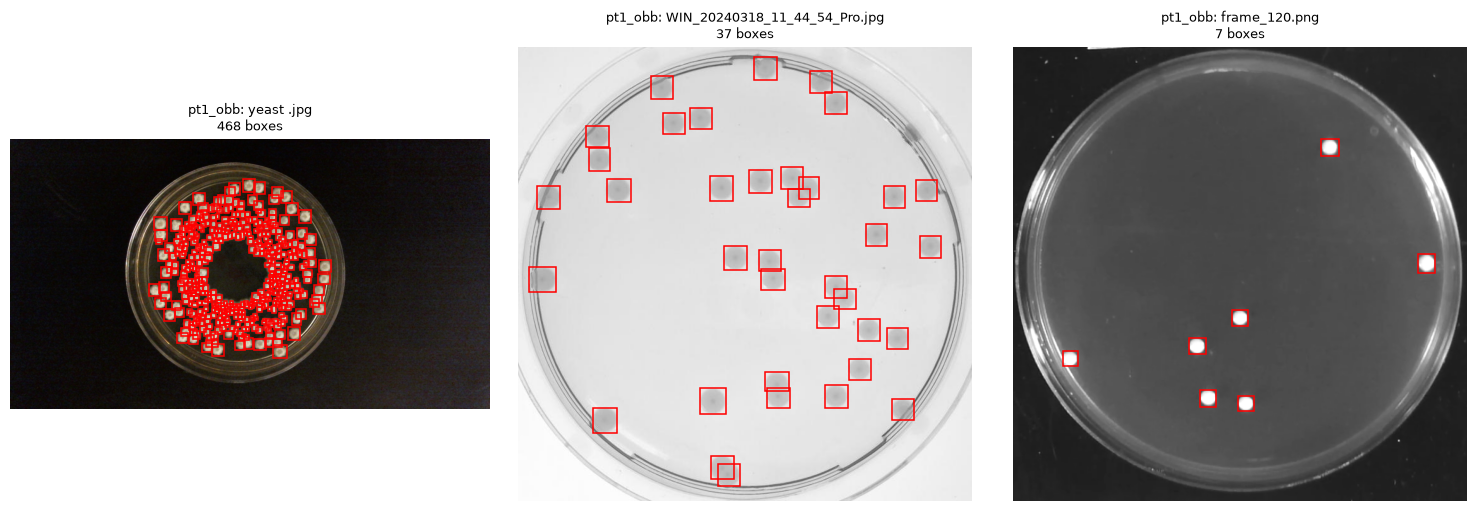

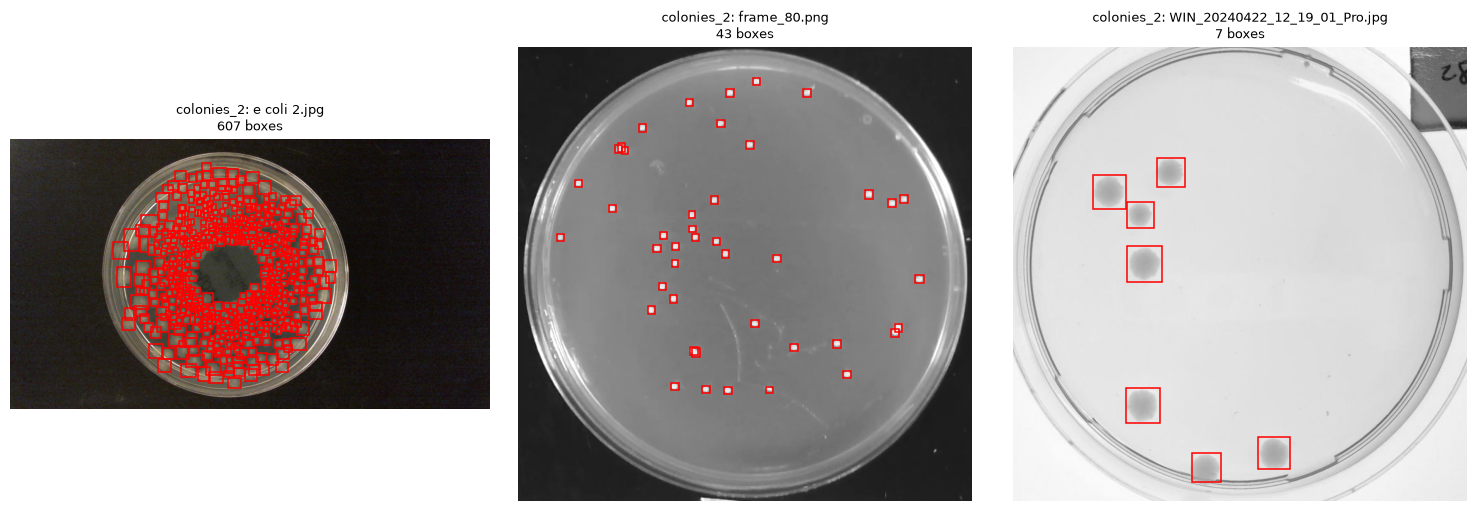

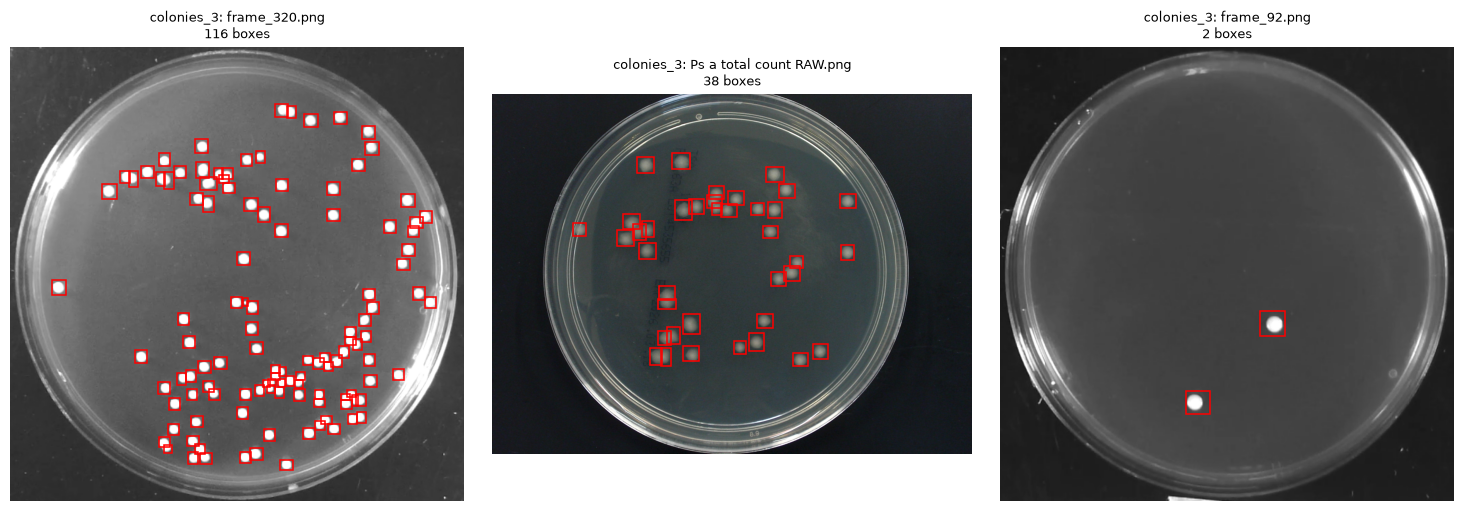

In [6]:
def overlay_boxes(image_path, records, ax, title):
    image = Image.open(image_path)
    array = np.asarray(image.convert('RGB') if image.mode != 'RGB' else image)
    height, width = array.shape[:2]
    ax.imshow(array)
    for _, xc, yc, w, h in records:
        x0 = (xc - w / 2) * width
        y0 = (yc - h / 2) * height
        ax.add_patch(plt.Rectangle((x0, y0), w * width, h * height, fill=False, color='red', linewidth=1.1))
    ax.set_title(f'{title}\n{len(records)} boxes', fontsize=9)
    ax.axis('off')


def pick_overlay_paths(source, n=3):
    subset = inventory[inventory['source'] == source].copy()
    subset = subset[subset['readable']].sort_values('objects', ascending=False)
    chosen = []
    if len(subset):
        chosen.append(subset.iloc[0])  # densest
    if len(subset) > 2:
        chosen.append(subset.iloc[len(subset) // 2])
        chosen.append(subset.iloc[-1])  # sparsest
    elif len(subset) > 1:
        chosen.append(subset.iloc[-1])
    return chosen[:n]


lookup = {(s['source'], s['original_name']): s for s in samples}

if SHOW_PLOTS:
    for source in ('pt1_obb', 'colonies_2', 'colonies_3'):
        rows = pick_overlay_paths(source, n=3)
        figure, axes = plt.subplots(1, len(rows), figsize=(5 * len(rows), 5), squeeze=False)
        for axis, row in zip(axes[0], rows):
            sample = lookup[(source, row['file'])]
            overlay_boxes(sample['image_path'], sample['records'], axis, f"{source}: {Path(row['file']).name}")
        plt.tight_layout()
        plt.show()


## 5. Frozen train / validation split of the full dataset

Validation is **20% of all 59 images**, stratified by annotator batch and by colony density (sparse / medium / dense). The same split is reused for every nano model and every augmentation experiment so mAP numbers are comparable.

`colonies_3` is **not** held out as extra training-only data: it is part of the complete labelled set.


In [7]:
DATASET_ROOT = WORK_ROOT / 'ultralytics' / 'full_dataset'
SPLIT_CSV = WORK_ROOT / 'full_split.csv'
RUNS_ROOT = WORK_ROOT / 'runs'
DEPLOY_ROOT = WORK_ROOT / 'deployment'


def density_bin(n_objects):
    if n_objects < 30:
        return 'sparse'
    if n_objects < 100:
        return 'medium'
    return 'dense'


def reset_dataset(root):
    if root.exists():
        shutil.rmtree(root)
    for split in ('train', 'val'):
        (root / 'images' / split).mkdir(parents=True, exist_ok=True)
        (root / 'labels' / split).mkdir(parents=True, exist_ok=True)


def copy_pair(root, split, image_path, records, prefix):
    stem = f'{prefix}_{sanitize_stem(image_path.name)}'
    dest_image = root / 'images' / split / f'{stem}{image_path.suffix.lower()}'
    dest_label = root / 'labels' / split / f'{stem}.txt'
    shutil.copy2(image_path, dest_image)
    write_yolo_txt(dest_label, records)
    return dest_image, dest_label


def write_yaml(root):
    yaml_path = root / 'colonies.yaml'
    yaml_path.write_text(
        f'path: {root.resolve().as_posix()}\n'
        'train: images/train\n'
        'val: images/val\n'
        'names:\n  0: colony\n',
        encoding='utf-8',
    )
    return yaml_path


usable = []
for sample in samples:
    if sample['image_path'] is None:
        print('Skipping missing image:', sample['source'], sample['original_name'])
        continue
    usable.append(sample)

split_frame = pd.DataFrame([
    {
        'source': sample['source'],
        'file': sample['original_name'],
        'objects': len(sample['records']),
        'density': density_bin(len(sample['records'])),
        'index': index,
    }
    for index, sample in enumerate(usable)
])
split_frame['stratum'] = split_frame['source'] + '_' + split_frame['density']

rng = np.random.default_rng(RANDOM_STATE)
val_indices = set()
for stratum, group in split_frame.groupby('stratum'):
    indices = group['index'].to_numpy()
    rng.shuffle(indices)
    n_val = max(1, int(round(VAL_FRACTION * len(indices)))) if len(indices) >= 4 else (1 if len(indices) >= 3 else 0)
    val_indices.update(indices[:n_val].tolist())

reset_dataset(DATASET_ROOT)
prefix_map = {'pt1_obb': 'pt1', 'colonies_2': 'c2', 'colonies_3': 'c3'}
split_rows = []
for index, sample in enumerate(usable):
    split = 'val' if index in val_indices else 'train'
    copy_pair(DATASET_ROOT, split, sample['image_path'], sample['records'], prefix_map[sample['source']])
    split_rows.append({
        'source': sample['source'],
        'file': sample['original_name'],
        'split': split,
        'objects': len(sample['records']),
        'density': density_bin(len(sample['records'])),
    })

split_table = pd.DataFrame(split_rows)
split_table.to_csv(SPLIT_CSV, index=False)
data_yaml = write_yaml(DATASET_ROOT)
display(split_table.groupby(['split', 'source']).agg(images=('file', 'count'), objects=('objects', 'sum')))
display(split_table.groupby('split').agg(images=('file', 'count'), objects=('objects', 'sum')))
print(data_yaml.read_text())
print('Val images:', sorted(split_table.loc[split_table['split'] == 'val', 'file'].map(lambda n: Path(n).name).tolist()))
print('Max objects in any image:', int(split_table['objects'].max()), '| max_det will be', YOLO_MAX_DET)


images  objects
split source                     
train colonies_2      16     1683
      colonies_3      16      695
      pt1_obb         16     1534
val   colonies_2       4      520
      colonies_3       3      113
      pt1_obb          4      359

,images,objects
split,,
train,48,3912
val,11,992


path: /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_full_work/ultralytics/full_dataset
train: images/train
val: images/val
names:
  0: colony

Val images: ['39 open.jpg', '40 open.jpg', 'Ps a total count RAW.png', 'Ps fluorescenes c.jpg', 'R mucilaginosa.jpg', 'Staph 3 RAW.png', 'WIN_20240318_11_44_54_Pro.jpg', 'WIN_20240422_12_06_15_Pro.jpg', 'frame_106.png', 'frame_361.png', 'frame_94.png']
Max objects in any image: 607 | max_det will be 700


## 6. Colony-reasonable augmentations

Colonies are **mostly circular** spots on a plate. Photometric changes and orientation changes are valid. Affine shears and plate-mixing are not.

| Transform | Use? | Why |
|---|---|---|
| HSV (hue / saturation / value) | yes | lighting, camera white-balance, agar colour |
| Horizontal + vertical flip | yes | a petri dish has no canonical up |
| Rotation | yes | circles stay circles; plates are rotated in the lab |
| Modest translate / scale | yes | framing and zoom vary |
| Mosaic | later experiment | helps tiny crowded colonies; can cut plates unnaturally |
| Shear / perspective | **no** | turns circles into ellipses |
| MixUp / CutMix | **no** | blends two plates into a non-physical image |
| Random erase | **no** | punches holes in colonies |
| Copy-paste | **no** in this notebook | can help counts, but pastes colonies onto unrealistic backgrounds |

Section 7 compares nano architectures with a **fair, mild** preset (flips + HSV, no mosaic, no rotation). Section 8 then searches augmentations on the winning architecture.


In [8]:
FAIR_AUG = {
    'hsv_h': 0.015,
    'hsv_s': 0.5,
    'hsv_v': 0.4,
    'degrees': 0.0,
    'translate': 0.05,
    'scale': 0.15,
    'shear': 0.0,
    'perspective': 0.0,
    'flipud': 0.5,
    'fliplr': 0.5,
    'mosaic': 0.0,
    'mixup': 0.0,
    'copy_paste': 0.0,
    'erasing': 0.0,
}

AUG_EXPERIMENTS = {
    'photometric_flips': {
        **FAIR_AUG,
    },
    'circular_geometry': {
        **FAIR_AUG,
        'degrees': 180.0,   # rotation-invariant circular objects
        'translate': 0.10,
        'scale': 0.30,
        'flipud': 0.5,
        'fliplr': 0.5,
        'mosaic': 0.0,
    },
    'circular_plus_mosaic': {
        **FAIR_AUG,
        'degrees': 180.0,
        'translate': 0.10,
        'scale': 0.30,
        'mosaic': 0.8,      # only extra transform: mosaic for small colonies
    },
}

display(pd.DataFrame(AUG_EXPERIMENTS).T)


,hsv_h,hsv_s,hsv_v,degrees,translate,scale,shear,perspective,flipud,fliplr,mosaic,mixup,copy_paste,erasing
photometric_flips,0.015,0.5,0.4,0.0,0.05,0.15,0.0,0.0,0.5,0.5,0.0,0.0,0.0,0.0
circular_geometry,0.015,0.5,0.4,180.0,0.10,0.30,0.0,0.0,0.5,0.5,0.0,0.0,0.0,0.0
circular_plus_mosaic,0.015,0.5,0.4,180.0,0.10,0.30,0.0,0.0,0.5,0.5,0.8,0.0,0.0,0.0


## 7. Compare YOLO nano versions on the full dataset

Each run starts from the official COCO-pretrained nano checkpoint, trains on the frozen split, and is scored with precision, recall, mAP50 and mAP50-95. The architecture with the highest **mAP50** (tie-break: mAP50-95) goes to the augmentation search.


In [9]:
def train_yolo(checkpoint, run_name, aug, epochs=None):
    epochs = YOLO_EPOCHS if epochs is None else epochs
    model = YOLO(checkpoint)
    model.train(
        data=str(data_yaml),
        epochs=epochs,
        imgsz=YOLO_IMGSZ,
        batch=YOLO_BATCH,
        device=YOLO_DEVICE,
        workers=YOLO_WORKERS,
        amp=YOLO_AMP,
        seed=RANDOM_STATE,
        project=str(RUNS_ROOT),
        name=run_name,
        exist_ok=True,
        plots=True,
        patience=20 if not SMOKE_TEST else 5,
        cos_lr=True,
        max_det=YOLO_MAX_DET,
        close_mosaic=10 if aug.get('mosaic', 0) else 0,
        hsv_h=aug['hsv_h'],
        hsv_s=aug['hsv_s'],
        hsv_v=aug['hsv_v'],
        degrees=aug['degrees'],
        translate=aug['translate'],
        scale=aug['scale'],
        shear=aug['shear'],
        perspective=aug['perspective'],
        flipud=aug['flipud'],
        fliplr=aug['fliplr'],
        mosaic=aug['mosaic'],
        mixup=aug['mixup'],
        copy_paste=aug['copy_paste'],
        erasing=aug['erasing'],
        verbose=True,
    )
    return RUNS_ROOT / run_name / 'weights' / 'best.pt'


def evaluate_yolo(checkpoint, run_name):
    model = YOLO(str(checkpoint))
    metrics = model.val(
        data=str(data_yaml),
        split='val',
        imgsz=YOLO_IMGSZ,
        device=YOLO_DEVICE,
        workers=YOLO_WORKERS,
        max_det=YOLO_MAX_DET,
        plots=True,
        verbose=False,
        project=str(RUNS_ROOT),
        name=run_name + '_val',
        exist_ok=True,
    )
    row = {
        'run': run_name,
        'checkpoint': str(checkpoint),
        'precision': float(metrics.box.mp),
        'recall': float(metrics.box.mr),
        'mAP50': float(metrics.box.map50),
        'mAP50-95': float(metrics.box.map),
    }
    return model, pd.DataFrame([row])


nano_rows = []
nano_weights = {}
if RUN_TRAINING:
    for model_name, checkpoint in NANO_MODELS.items():
        run_name = f'full_{model_name.lower()}_fair'
        print('\n========', model_name, '========')
        try:
            best_path = train_yolo(checkpoint, run_name, FAIR_AUG)
        except Exception as exc:
            print('Training failed for', model_name, ':', exc)
            continue
        if not best_path.exists():
            print('Missing weights for', run_name)
            continue
        nano_weights[model_name] = best_path
        _, metrics = evaluate_yolo(best_path, run_name)
        metrics.insert(0, 'model', model_name)
        metrics.insert(1, 'stage', 'architecture')
        nano_rows.append(metrics)
else:
    print('Training skipped. Set RUN_TRAINING=True.')

nano_table = pd.concat(nano_rows, ignore_index=True) if nano_rows else pd.DataFrame(
    columns=['model', 'stage', 'run', 'precision', 'recall', 'mAP50', 'mAP50-95']
)
if len(nano_table):
    nano_table = nano_table.sort_values(['mAP50', 'mAP50-95'], ascending=False).reset_index(drop=True)
    display(nano_table)
    nano_table.to_csv(WORK_ROOT / 'nano_architecture_metrics.csv', index=False)
    best_model_name = nano_table.iloc[0]['model']
    print('Best nano architecture:', best_model_name)
else:
    best_model_name = 'YOLO11n'
    print('No architecture metrics yet; defaulting later stages to', best_model_name)



======== YOLOv8n ========
New https://pypi.org/project/ultralytics/8.4.219 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.182 🚀 Python-3.11.16 torch-2.14.1+cu130 CPU (13th Gen Intel Core i7-13700H)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_full_work/ultralytics/full_dataset/colonies.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.0, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, i

2026/11/26 14:28:27 INFO mlflow.tracking.fluent: Experiment with name '/home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_full_work/runs' does not exist. Creating a new experiment.


MLflow: logging run_id(925cb37de4df41ae943c5a41fd3bcbb6) to sqlite:////home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/mlflow.db
MLflow: disable with 'yolo settings mlflow=False'
Using 48 train, 11 val images for fraction=1.0 at imgsz=640
Using 0 dataloader workers
Logging results to /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_full_work/runs/full_yolov8n_fair
Starting training for 50 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/50         0G      2.059      3.011      1.054        182        640: 100% ━━━━━━━━━━━━ 12/12 1.1it/s 11.3s0.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.4it/s 1.4s4.0s
                   all         11        992      0.317       0.24      0.175     0.0631

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/50         0G      1.905      2.195     0

,model,stage,run,checkpoint,precision,recall,mAP50,mAP50-95
0,YOLO11n,architecture,full_yolo11n_fair,/home/nikolaieva/ML/KSE_ML_for_bioinformatics/...,0.841948,0.622919,0.672368,0.374259
1,YOLO26n,architecture,full_yolo26n_fair,/home/nikolaieva/ML/KSE_ML_for_bioinformatics/...,0.795715,0.621976,0.658140,0.355865
2,YOLOv8n,architecture,full_yolov8n_fair,/home/nikolaieva/ML/KSE_ML_for_bioinformatics/...,0.786298,0.629032,0.649835,0.358823


Best nano architecture: YOLO11n


## 8. Augmentation search on the best nano

The winning architecture is retrained from its **pretrained** nano weights (not from the previous fine-tune) so each recipe gets the same number of epochs. Only the three colony-reasonable recipes from section 6 are used.


In [10]:
aug_rows = []
aug_weights = {}
best_checkpoint_name = NANO_MODELS.get(best_model_name, 'yolo11n.pt')

if RUN_TRAINING and RUN_AUGMENTATION:
    # photometric_flips == FAIR_AUG, already trained during architecture comparison.
    if len(nano_table) and nano_weights.get(best_model_name):
        reused = nano_table[nano_table['model'] == best_model_name].copy()
        reused['stage'] = 'augmentation'
        reused.insert(2, 'recipe', 'photometric_flips')
        aug_rows.append(reused)
        aug_weights['photometric_flips'] = nano_weights[best_model_name]
        print('Reused fair-architecture run as photometric_flips (same transforms).')

    for recipe_name, aug in AUG_EXPERIMENTS.items():
        if recipe_name == 'photometric_flips':
            continue
        run_name = f'full_{best_model_name.lower()}_{recipe_name}'
        print('\n========', best_model_name, recipe_name, '========')
        try:
            best_path = train_yolo(best_checkpoint_name, run_name, aug)
        except Exception as exc:
            print('Training failed for', recipe_name, ':', exc)
            continue
        if not best_path.exists():
            print('Missing weights for', run_name)
            continue
        aug_weights[recipe_name] = best_path
        _, metrics = evaluate_yolo(best_path, run_name)
        metrics.insert(0, 'model', best_model_name)
        metrics.insert(1, 'stage', 'augmentation')
        metrics.insert(2, 'recipe', recipe_name)
        aug_rows.append(metrics)
else:
    print('Augmentation search skipped.')

aug_table = pd.concat(aug_rows, ignore_index=True) if aug_rows else pd.DataFrame()
if len(aug_table):
    aug_table = aug_table.sort_values(['mAP50', 'mAP50-95'], ascending=False).reset_index(drop=True)
    display(aug_table)
    aug_table.to_csv(WORK_ROOT / 'nano_augmentation_metrics.csv', index=False)
    best_recipe = aug_table.iloc[0]['recipe']
    print('Best augmentation recipe:', best_recipe)
else:
    best_recipe = 'circular_geometry'
    print('No augmentation metrics yet; default recipe', best_recipe)

comparison = pd.concat(
    [df for df in (nano_table, aug_table) if len(df)],
    ignore_index=True,
    sort=False,
)
if len(comparison):
    display(comparison)
    comparison.to_csv(WORK_ROOT / 'all_training_metrics.csv', index=False)


Reused fair-architecture run as photometric_flips (same transforms).

======== YOLO11n circular_geometry ========
New https://pypi.org/project/ultralytics/8.4.219 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.182 🚀 Python-3.11.16 torch-2.14.1+cu130 CPU (13th Gen Intel Core i7-13700H)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_full_work/ultralytics/full_dataset/colonies.yaml, degrees=180.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.0, exist_ok=True, fliplr=0.5, flipud=0.5, forma

,model,stage,recipe,run,checkpoint,precision,recall,mAP50,mAP50-95
0,YOLO11n,augmentation,photometric_flips,full_yolo11n_fair,/home/nikolaieva/ML/KSE_ML_for_bioinformatics/...,0.841948,0.622919,0.672368,0.374259
1,YOLO11n,augmentation,circular_geometry,full_yolo11n_circular_geometry,/home/nikolaieva/ML/KSE_ML_for_bioinformatics/...,0.742955,0.534274,0.546997,0.158492
2,YOLO11n,augmentation,circular_plus_mosaic,full_yolo11n_circular_plus_mosaic,/home/nikolaieva/ML/KSE_ML_for_bioinformatics/...,0.738818,0.561757,0.533817,0.182919


Best augmentation recipe: photometric_flips


,model,stage,run,checkpoint,precision,recall,mAP50,mAP50-95,recipe
0,YOLO11n,architecture,full_yolo11n_fair,/home/nikolaieva/ML/KSE_ML_for_bioinformatics/...,0.841948,0.622919,0.672368,0.374259,NaN
1,YOLO26n,architecture,full_yolo26n_fair,/home/nikolaieva/ML/KSE_ML_for_bioinformatics/...,0.795715,0.621976,0.658140,0.355865,NaN
2,YOLOv8n,architecture,full_yolov8n_fair,/home/nikolaieva/ML/KSE_ML_for_bioinformatics/...,0.786298,0.629032,0.649835,0.358823,NaN
3,YOLO11n,augmentation,full_yolo11n_fair,/home/nikolaieva/ML/KSE_ML_for_bioinformatics/...,0.841948,0.622919,0.672368,0.374259,photometric_flips
4,YOLO11n,augmentation,full_yolo11n_circular_geometry,/home/nikolaieva/ML/KSE_ML_for_bioinformatics/...,0.742955,0.534274,0.546997,0.158492,circular_geometry
5,YOLO11n,augmentation,full_yolo11n_circular_plus_mosaic,/home/nikolaieva/ML/KSE_ML_for_bioinformatics/...,0.738818,0.561757,0.533817,0.182919,circular_plus_mosaic


## 9. Ground truth vs predictions on the validation split

Look at missed colonies (especially dense plates), extra boxes on glare or the rim, and whether boxes stay tight on circular colonies.


Weights used for visual QA: /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_full_work/runs/full_yolo11n_fair/weights/best.pt


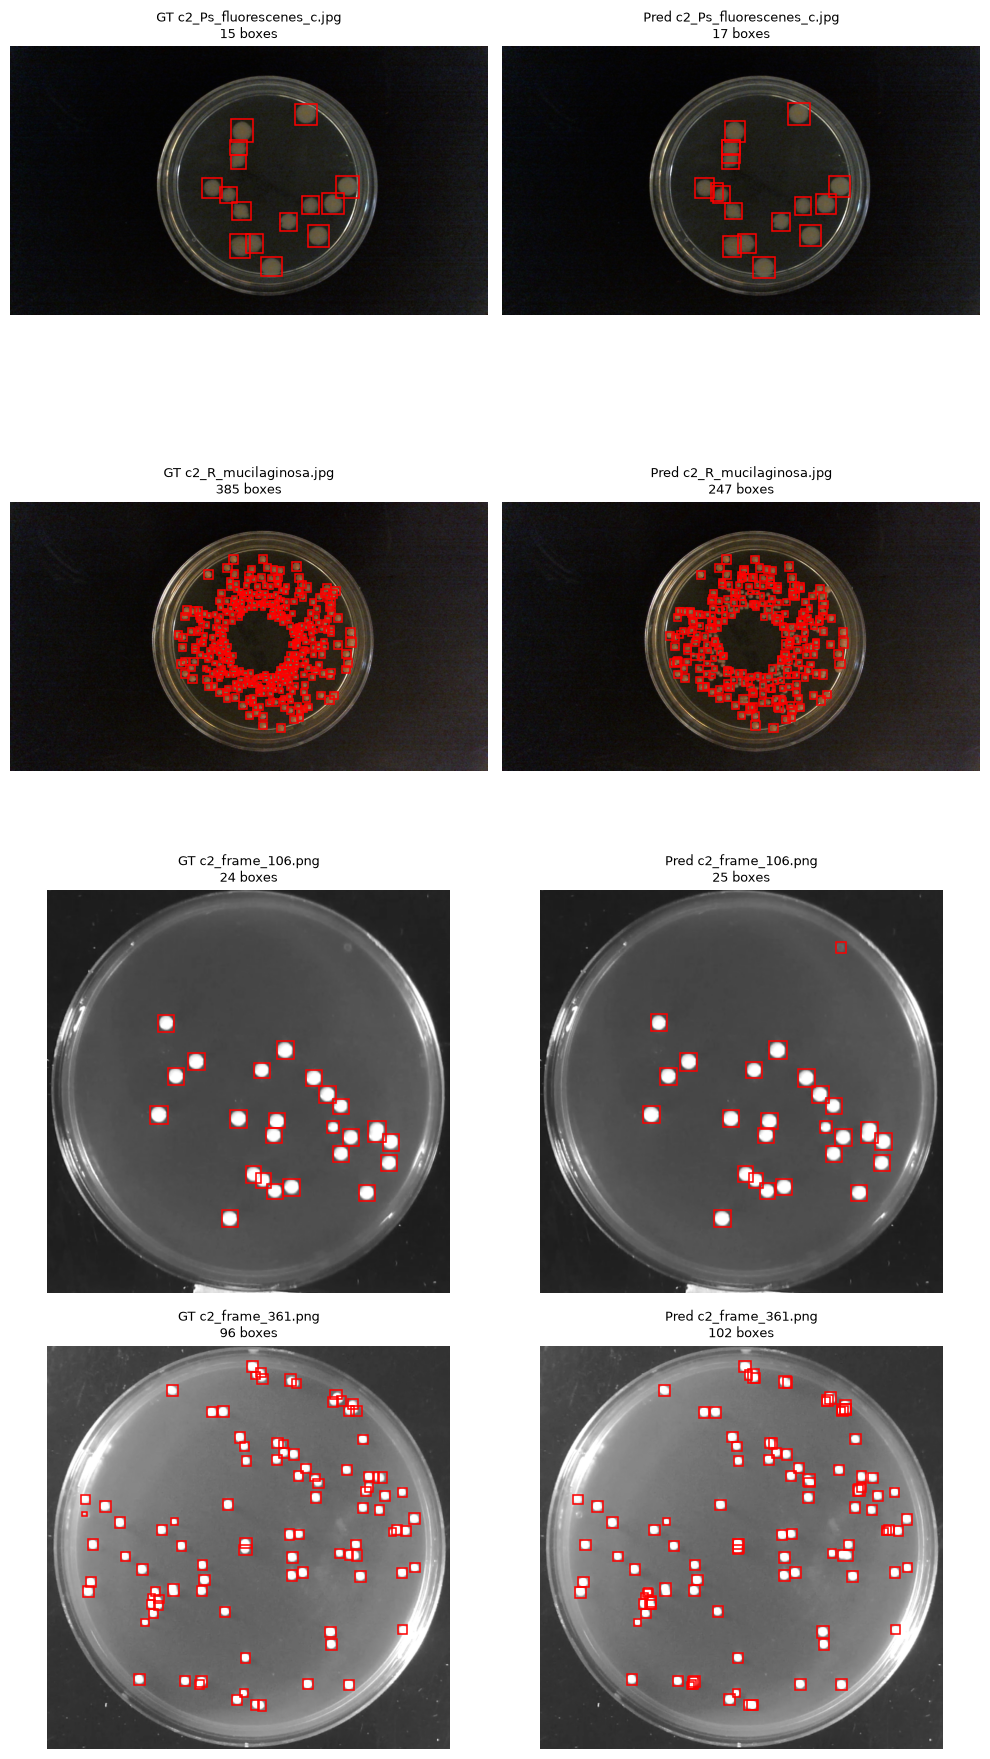

In [12]:
def resolve_best_weights():
    candidates = []
    if len(aug_table):
        candidates.append(Path(aug_table.iloc[0]['checkpoint']))
    if len(nano_table):
        candidates.append(Path(nano_table.iloc[0]['checkpoint']))
    for path in candidates:
        if path.exists():
            return path
    fallback = RUNS_ROOT.glob('**/weights/best.pt')
    return next(fallback, None)


best_weights = resolve_best_weights()
print('Weights used for visual QA:', best_weights)

val_dir = DATASET_ROOT / 'images' / 'val'
val_images = sorted(val_dir.glob('*'))
show_n = min(4, len(val_images))

if SHOW_PLOTS and best_weights is not None and show_n:
    qa_model = YOLO(str(best_weights))
    figure, axes = plt.subplots(show_n, 2, figsize=(10, 4.5 * show_n), squeeze=False)
    for row, image_path in enumerate(val_images[:show_n]):
        label_path = DATASET_ROOT / 'labels' / 'val' / f'{image_path.stem}.txt'
        records = parse_obb_label(label_path) if label_path.exists() else []
        overlay_boxes(image_path, records, axes[row, 0], f'GT {image_path.name}')
        prediction = qa_model.predict(
            source=str(image_path),
            imgsz=YOLO_IMGSZ,
            device=YOLO_DEVICE,
            max_det=YOLO_MAX_DET,
            conf=0.25,
            verbose=False,
        )[0]
        pred_records = []
        if prediction.boxes is not None and len(prediction.boxes):
            xywhn = prediction.boxes.xywhn.cpu().numpy()
            cls = prediction.boxes.cls.cpu().numpy()
            for class_id, (xc, yc, w, h) in zip(cls, xywhn):
                pred_records.append((int(class_id), float(xc), float(yc), float(w), float(h)))
        overlay_boxes(image_path, pred_records, axes[row, 1], f'Pred {image_path.name}')
    plt.tight_layout()
    plt.show()
else:
    print('Skip GT vs pred overlay.')


## 10. Save the best model for deployment

The winning `best.pt` is copied next to an ONNX graph and a small JSON sidecar (class name, image size, `max_det`, metrics). Those files are what you load in a counting app or a CVAT model-assisted workflow — not the Ultralytics `runs/` folder.


In [13]:
DEPLOY_ROOT.mkdir(parents=True, exist_ok=True)

if RUN_EXPORT and best_weights is not None and Path(best_weights).exists():
    dest_pt = DEPLOY_ROOT / 'colony_yolo_nano.pt'
    shutil.copy2(best_weights, dest_pt)
    print('Copied PyTorch weights ->', dest_pt)

    deploy_model = YOLO(str(dest_pt))
    export_paths = {}
    for fmt in ('onnx', 'torchscript'):
        try:
            exported = deploy_model.export(format=fmt, imgsz=YOLO_IMGSZ, simplify=(fmt == 'onnx'))
            export_paths[fmt] = str(exported)
            print('Exported', fmt, '->', exported)
        except Exception as exc:
            print('Export failed for', fmt, ':', exc)

    metrics_row = {}
    if len(aug_table):
        metrics_row = aug_table.iloc[0].to_dict()
    elif len(nano_table):
        metrics_row = nano_table.iloc[0].to_dict()

    sidecar = {
        'task': 'detect',
        'class_names': ['colony'],
        'architecture': best_model_name,
        'augmentation_recipe': best_recipe if RUN_AUGMENTATION else 'fair',
        'imgsz': YOLO_IMGSZ,
        'max_det': YOLO_MAX_DET,
        'conf_default': 0.25,
        'iou_default': 0.7,
        'device_trained': str(YOLO_DEVICE),
        'epochs': YOLO_EPOCHS,
        'weights_pt': str(dest_pt),
        'exports': export_paths,
        'metrics': {k: metrics_row.get(k) for k in ('precision', 'recall', 'mAP50', 'mAP50-95')},
        'data_yaml': str(data_yaml),
        'split_csv': str(SPLIT_CSV),
    }
    sidecar_path = DEPLOY_ROOT / 'colony_yolo_nano_meta.json'
    sidecar_path.write_text(json.dumps(sidecar, indent=2), encoding='utf-8')
    print('Wrote', sidecar_path)

    # Move ONNX/TorchScript next to the sidecar if Ultralytics left them beside the .pt
    for generated in dest_pt.parent.glob('colony_yolo_nano.*'):
        if generated.suffix.lower() in {'.onnx', '.torchscript', '.engine'}:
            print('Deployment artefact:', generated)
else:
    print('Export skipped. Set RUN_EXPORT=True after training.')

print('\nDeployment folder:', DEPLOY_ROOT)
if DEPLOY_ROOT.exists():
    for path in sorted(DEPLOY_ROOT.rglob('*')):
        if path.is_file():
            print(' -', path.relative_to(DEPLOY_ROOT), f'({path.stat().st_size / 1e6:.2f} MB)')


Copied PyTorch weights -> /home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_full_work/deployment/colony_yolo_nano.pt
Ultralytics 8.4.182 🚀 Python-3.11.16 torch-2.14.1+cu130 CPU (13th Gen Intel Core i7-13700H)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/home/nikolaieva/ML/KSE_ML_for_bioinformatics/practicals/week7/homework/yolo_full_work/deployment/colony_yolo_nano.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (5.3 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.11.16 environment at: /home/nikolaieva/ML/KSE_ML_for_bioinformatics/.venv
Resolved 12 packages in 511ms
 Downloaded onnx
 Downloaded onnxruntime
Prepared 4 packages i

## 11. How to load the deployed model

```python
from ultralytics import YOLO
model = YOLO('homework/yolo_full_work/deployment/colony_yolo_nano.pt')
result = model.predict('plate.jpg', imgsz=640, max_det=700, conf=0.25)[0]
n_colonies = len(result.boxes)
```

ONNX is the portable option if the production environment should not depend on Ultralytics training code.

**Reading the scores.** Detection still does not report classification accuracy. Use precision, recall, mAP50 and mAP50-95 from `all_training_metrics.csv`. If mosaic helps crowded plates but hurts sparse ones, say so from the GT vs prediction figure rather than from mAP alone.
